In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate, RandomizedSearchCV, learning_curve
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor

from pathlib import Path
import data_loader

np.random.seed(42) # reproducible results

In [27]:
data_dir = Path("data")
X_train, X_test, y_train = data_loader.get_train_test_dfs(data_dir)
#X_train = X_train.drop(columns=["CantonName", "CommuneName", "Einheit"])
#X_test = X_test.drop(columns=["CantonName", "CommuneName", "Einheit"])
y_train = y_train.values.squeeze()

In [35]:
param_grid_boost = {
    'regressor__n_estimators' : [i for i in range(50, 550, 50)],
    'regressor__learning_rate' : [0.2, 0.1, 0.05, 0.01],
    'regressor__max_depth' : [i for i in range(1, 5)],
    'regressor__subsample' : [0.6, 0.8, 1.0], # can minimise overfitting
    'regressor__min_samples_split' : [2, 5, 10],
    'regressor__min_samples_leaf' : [2, 5, 10]
}

In [36]:
gbr = GradientBoostingRegressor(random_state=0)
model = Pipeline(steps=[('imputer', SimpleImputer(strategy='mean')), ('regressor', gbr)])
grid = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid_boost,
    cv=20,
    scoring='neg_root_mean_squared_error',
    n_iter=20,
    random_state=0,
    n_jobs=-1,
    return_train_score=True
)
grid.fit(X_train, y_train)
best_cv_rmse = -grid.cv_results_['mean_test_score'][grid.best_index_]
best_train_rmse = -grid.cv_results_['mean_train_score'][grid.best_index_]

print("Best CV RMSE :", best_cv_rmse)
print("Best train RMSE :", best_train_rmse)
print("Best params:\n", grid.best_params_)

Best CV RMSE : 5.9685284381059756
Best train RMSE : 3.6683799571718607
Best params:
 {'regressor__subsample': 0.8, 'regressor__n_estimators': 250, 'regressor__min_samples_split': 2, 'regressor__min_samples_leaf': 10, 'regressor__max_depth': 3, 'regressor__learning_rate': 0.05}


In [34]:
train_test_ratio = best_cv_rmse / best_train_rmse
print("Ratio between train and test :", train_test_ratio) # overfit indicator

Ratio between train and test : 1.5105069235465556


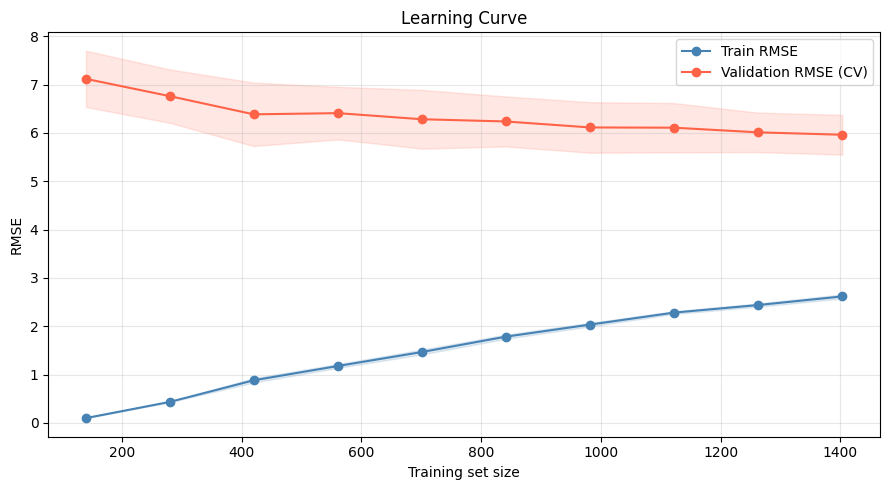

In [24]:
# See bias and variance
train_sizes, train_scores, val_scores = learning_curve(best_model, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=10,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

train_rmse = -train_scores.mean(axis=1)
val_rmse   = -val_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_std    = val_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(train_sizes, train_rmse, 'o-', color='steelblue', label='Train RMSE')
ax.fill_between(train_sizes, train_rmse - train_std, train_rmse + train_std, alpha=0.15, color='steelblue')
ax.plot(train_sizes, val_rmse, 'o-', color='tomato', label='Validation RMSE (CV)')
ax.fill_between(train_sizes, val_rmse - val_std, val_rmse + val_std, alpha=0.15, color='tomato')
ax.set_xlabel('Training set size')
ax.set_ylabel('RMSE')
ax.set_title('Learning Curve')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

                             feature  importance
              Agricultural area in %    0.270617
                                 lat    0.075217
          Population density per km²    0.043857
                          0-19 years    0.042430
                                 CVP    0.032653
                           CommuneID    0.030897
       Size of households in persons    0.030356
                          FDP/PLR 2)    0.028105
                                  SP    0.027681
                                 BDP    0.027241
                   Ja in Prozent_622    0.026061
                                 GPS    0.019656
                       median_stbetr    0.018486
                    65 years or over    0.018403
                                 lon    0.017859
              Unproductive area in %    0.016939
                Stimmbeteiligung_622    0.010920
                         mean_stbetr    0.010004
                      Primary sector    0.009313
            Small ri

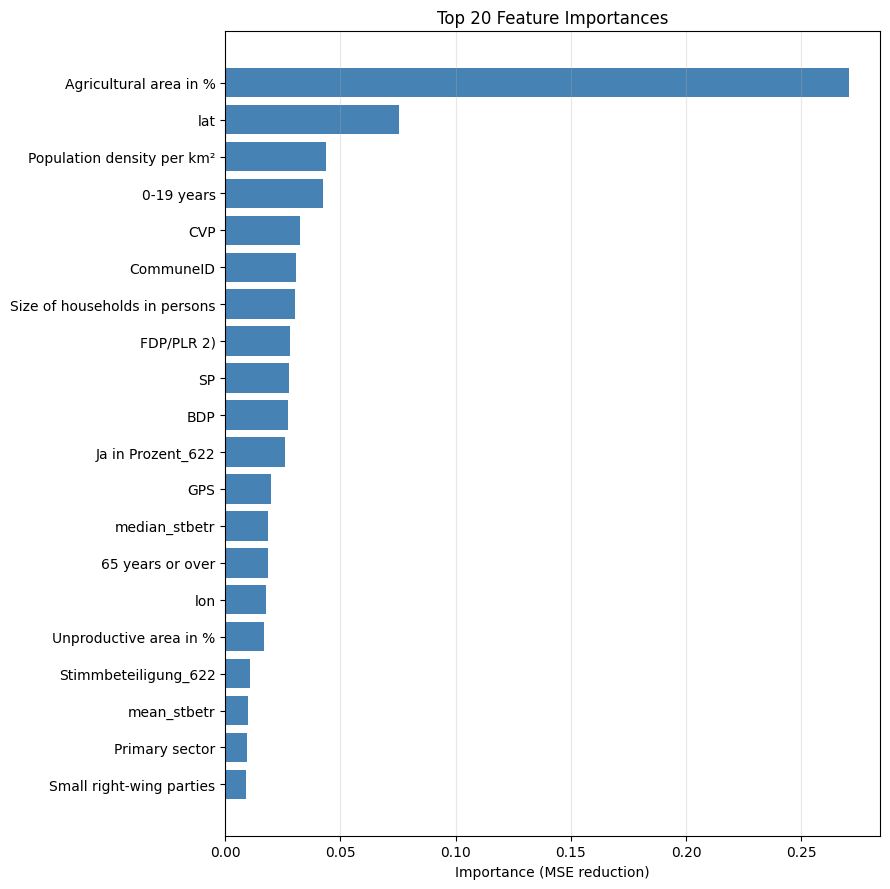

In [19]:

gbr_fitted   = best_model.named_steps['regressor']
importances  = gbr_fitted.feature_importances_

fi_df = pd.DataFrame({'feature': X_train.columns, 'importance': importances}).drop(columns=["CommuneID"])
fi_df = fi_df.sort_values('importance', ascending=False).reset_index(drop=True)

print(fi_df.to_string(index=False))

# Plot top-20 features
top_n = min(20, len(fi_df))
top_fi = fi_df.head(top_n)

fig, ax = plt.subplots(figsize=(9, top_n * 0.4 + 1))
bars = ax.barh(top_fi['feature'][::-1], top_fi['importance'][::-1], color='steelblue')
ax.set_xlabel('Importance (MSE reduction)')
ax.set_title(f'Top {top_n} Feature Importances')
ax.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [38]:
y_predict = grid.predict(X_test)

submission_df = pd.DataFrame({
    'Id': X_test["CommuneID"],
    'Predicted': y_predict
})

submission_df.to_csv("submission_boosting.csv", index=False)
print("Saved submission_boosting.csv for Kaggle.")

display(submission_df.head())

5.9685284381059756
Saved submission_boosting.csv for Kaggle.


,Id,Predicted
0,69,48.023529
1,981,41.298009
2,5432,34.195361
3,387,46.618296
4,2194,33.244675
